In [ ]:
import re
import requests
from urllib.parse import urlparse
from bs4 import BeautifulSoup

def extract_kaggle_features(url):
    parsed = urlparse(url)
    features = {}

    # ---------------- URL BASED ----------------
    features['length_url'] = len(url)
    features['length_hostname'] = len(parsed.netloc)
    features['nb_dots'] = url.count('.')
    features['nb_hyphens'] = url.count('-')
    features['nb_at'] = url.count('@')
    features['nb_qm'] = url.count('?')
    features['nb_and'] = url.count('&')
    features['nb_eq'] = url.count('=')
    features['nb_underscore'] = url.count('_')
    features['nb_tilde'] = url.count('~')
    features['nb_percent'] = url.count('%')
    features['nb_slash'] = url.count('/')
    features['nb_star'] = url.count('*')
    features['nb_colon'] = url.count(':')
    features['nb_comma'] = url.count(',')
    features['nb_semicolumn'] = url.count(';')
    features['nb_dollar'] = url.count('$')
    features['nb_space'] = url.count(' ')
    features['nb_www'] = url.count('www')
    features['nb_com'] = url.count('.com')
    features['nb_dslash'] = url.count('//')

    features['http_in_path'] = int("http" in parsed.path)
    features['https_token'] = int("https" in url)

    digits = sum(c.isdigit() for c in url)
    features['ratio_digits_url'] = digits / len(url) if len(url) else 0
    features['ratio_digits_host'] = digits / len(parsed.netloc) if parsed.netloc else 0

    features['punycode'] = int("xn--" in url)
    features['port'] = int(":" in parsed.netloc)

    features['tld_in_path'] = int("." in parsed.path)
    features['tld_in_subdomain'] = int(parsed.netloc.count('.') > 2)
    features['abnormal_subdomain'] = int(parsed.netloc.count('.') > 3)

    features['nb_subdomains'] = parsed.netloc.count('.')
    features['prefix_suffix'] = int('-' in parsed.netloc)
    features['random_domain'] = int(len(parsed.netloc) > 25)
    features['shortening_service'] = int(any(s in url for s in ["bit.ly", "tinyurl", "goo.gl"]))

    features['path_extension'] = int("." in parsed.path)

    # ---------------- CONTENT BASED ----------------
    try:
        response = requests.get(url, timeout=5)
        soup = BeautifulSoup(response.text, "html.parser")

        links = soup.find_all('a', href=True)
        features['nb_hyperlinks'] = len(links)

        features['iframe'] = int(len(soup.find_all('iframe')) > 0)
        features['popup_window'] = int("window.open" in response.text)
        features['safe_anchor'] = int("#" in response.text)

        features['empty_title'] = int(soup.title is None)
        features['domain_in_title'] = int(parsed.netloc in (soup.title.string if soup.title else ""))

        features['login_form'] = int(len(soup.find_all('form')) > 0)
        features['external_favicon'] = int("http" in str(soup.find("link", rel="icon")))

    except:
        # fallback if request fails
        features['nb_hyperlinks'] = 0
        features['iframe'] = 0
        features['popup_window'] = 0
        features['safe_anchor'] = 0
        features['empty_title'] = 1
        features['domain_in_title'] = 0
        features['login_form'] = 0
        features['external_favicon'] = 0

    # ---------------- HEURISTIC FEATURES ----------------
    suspicious_words = ["login", "verify", "update", "secure", "account"]
    features['phish_hints'] = int(any(word in url.lower() for word in suspicious_words))

    features['domain_in_brand'] = int("aadhaar" in url.lower())
    features['brand_in_path'] = int("aadhaar" in parsed.path.lower())

    features['suspecious_tld'] = int(parsed.netloc.endswith((".tk", ".ml", ".ga", ".cf")))

    # ---------------- PLACEHOLDER (ADVANCED FEATURES) ----------------
    # These require APIs (WHOIS, Alexa, Google)
    features['domain_age'] = 0
    features['web_traffic'] = 0
    features['google_index'] = 0
    features['page_rank'] = 0
    features['dns_record'] = 1

    return features

In [44]:
import pandas as pd

def build_dataset(urls, label):
    data = []
    for url in urls:
        f = extract_kaggle_features(url)
        f['url'] = url
        f['status'] = label
        data.append(f)
    return pd.DataFrame(data)

In [45]:
import pandas as pd

df_input = pd.read_csv("aadhar_dataset.csv")


In [5]:
data = []

for _, row in df_input.iterrows():
    url = row['url']
    label = row['status']
    
    f = extract_kaggle_features(url)   # your feature function
    f['url'] = url
    f['status'] = label
    
    data.append(f)

df_final = pd.DataFrame(data)

In [6]:
df_final.to_csv("final_aadhaar_dataset.csv", index=False)

In [7]:
X = df_final.drop(['url', 'status'], axis=1)
y = df_final['status']

Split Features and Target

In [9]:
import pandas as pd

df = pd.read_csv("final_aadhaar_dataset.csv")

In [10]:
X = df.drop(['url', 'status'], axis=1)
y = df['status']

🔹 Train-test split

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Scaling

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

🔹Train Model (Random Forest)

In [13]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

🔹 6. Predictions

In [14]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

Confusion Matrix

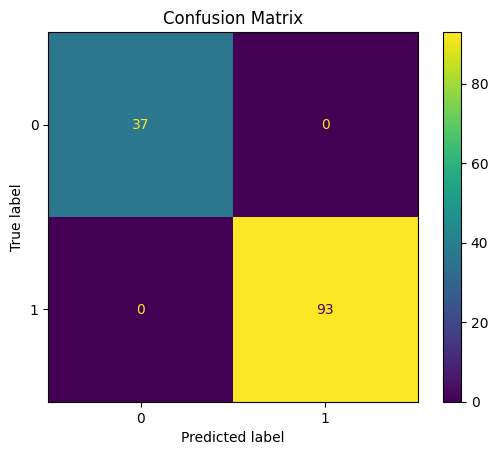

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Confusion Matrix")
plt.show()

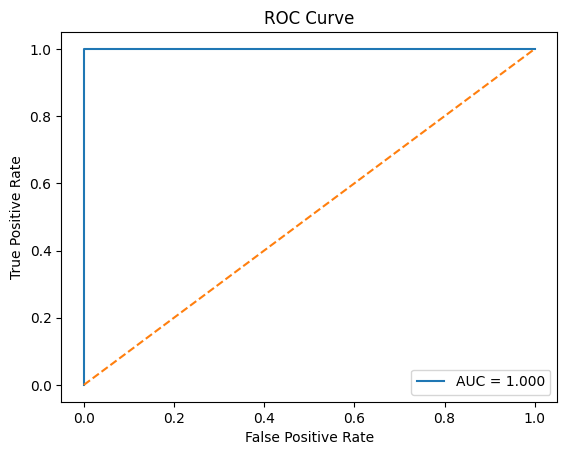

In [16]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test, y_prob, pos_label=1)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

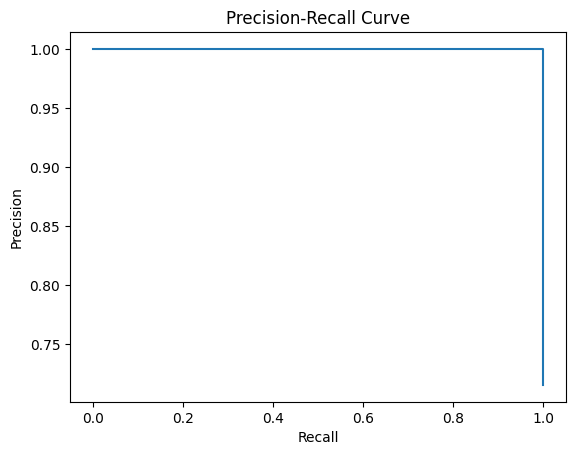

In [17]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_prob)

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

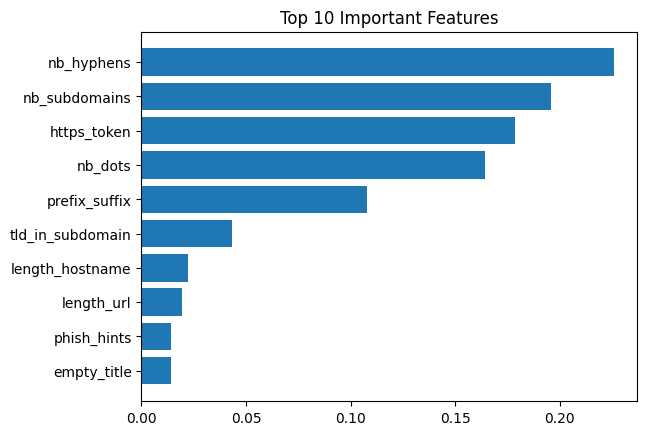

In [18]:
import pandas as pd

importances = model.feature_importances_
features = X.columns

feat_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

plt.barh(feat_df['Feature'], feat_df['Importance'])
plt.gca().invert_yaxis()

plt.title("Top 10 Important Features")
plt.show()

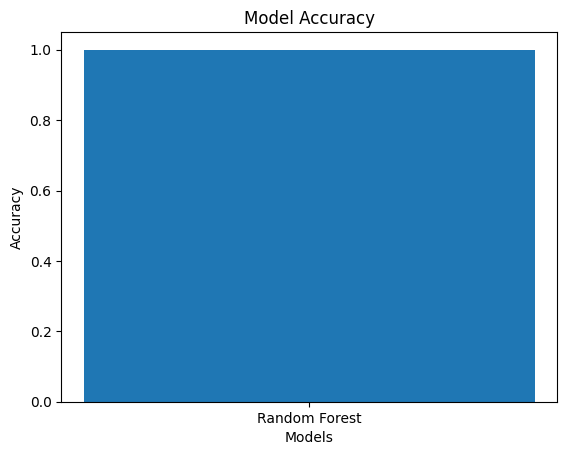

In [19]:
models = ['Random Forest']
accuracy = [model.score(X_test, y_test)]

plt.bar(models, accuracy)

plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")

plt.show()

In [20]:
df.shape

(650, 54)

In [21]:
def predict_url(url, model, scaler):
    # extract features
    features = extract_kaggle_features(url)
    
    import pandas as pd
    df = pd.DataFrame([features])
    
    # scale features
    df_scaled = scaler.transform(df)
    
    # predict
    pred = model.predict(df_scaled)[0]
    prob = model.predict_proba(df_scaled)[0][1]
    
    if pred == 1:
        print(f"⚠️ PHISHING WEBSITE (Confidence: {prob:.2f})")
    else:
        print(f"✅ LEGITIMATE WEBSITE (Confidence: {prob:.2f})")

In [34]:
predict_url("http://aadhaar.update.help.com", model, scaler)

✅ LEGITIMATE WEBSITE (Confidence: 0.25)


In [35]:
urls = [
    "https://uidai.gov.in",
    "http://aadhaar-fake-login.com"
]

for u in urls:
    print("\nTesting:", u)
    predict_url(u, model, scaler)


Testing: https://uidai.gov.in
✅ LEGITIMATE WEBSITE (Confidence: 0.00)

Testing: http://aadhaar-fake-login.com
⚠️ PHISHING WEBSITE (Confidence: 1.00)


In [36]:
print(df['status'].value_counts())

status
1    500
0    150
Name: count, dtype: int64


In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
forest_clf = RandomForestClassifier(max_depth=10, random_state=0)
forest_clf.fit(X_train,y_train)
ran_pred=forest_clf.predict(X_test)
accuracy_score(ran_pred,y_test)

1.0

In [39]:
print(X.columns)

Index(['length_url', 'length_hostname', 'nb_dots', 'nb_hyphens', 'nb_at',
       'nb_qm', 'nb_and', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent',
       'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn',
       'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash',
       'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host',
       'punycode', 'port', 'tld_in_path', 'tld_in_subdomain',
       'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain',
       'shortening_service', 'path_extension', 'nb_hyperlinks', 'iframe',
       'popup_window', 'safe_anchor', 'empty_title', 'domain_in_title',
       'login_form', 'external_favicon', 'phish_hints', 'domain_in_brand',
       'brand_in_path', 'suspecious_tld', 'domain_age', 'web_traffic',
       'google_index', 'page_rank', 'dns_record'],
      dtype='object')


In [40]:
print(len(X_train), len(X_test))

520 130


In [46]:
drop_cols = ['phish_hints', 'suspecious_tld']
X = X.drop(drop_cols, axis=1)

KeyError: "['phish_hints', 'suspecious_tld'] not found in axis"

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
forest_clf = RandomForestClassifier(max_depth=10, random_state=0)
forest_clf.fit(X_train,y_train)
ran_pred=forest_clf.predict(X_test)
accuracy_score(ran_pred,y_test)

1.0